In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
df=pd.read_csv("dataset_09.csv",header=None)

In [3]:
X = df.drop(df.columns[-1], axis=1)

print(df.head())
print("Dataset Shape:", df.shape)

   0    1         2   3      4       5    6    7    8    9   ...     32    33  \
0   0  tcp  ftp_data  SF  491.0     0.0  0.0  0.0  0.0  0.0  ...   25.0  0.17   
1   0  udp     other  SF  146.0     0.0  0.0  0.0  0.0  0.0  ...    1.0  0.00   
2   0  tcp   private  S0    0.0     0.0  0.0  0.0  0.0  0.0  ...   26.0  0.10   
3   0  tcp      http  SF  232.0  8153.0  0.0  0.0  0.0  0.0  ...  255.0  1.00   
4   0  tcp      http  SF  199.0   420.0  0.0  0.0  0.0  0.0  ...  255.0  1.00   

     34    35    36    37    38    39    40       41  
0  0.03  0.17  0.00  0.00  0.00  0.05  0.00   normal  
1  0.60  0.88  0.00  0.00  0.00  0.00  0.00   normal  
2  0.05  0.00  0.00  1.00  1.00  0.00  0.00  neptune  
3  0.00  0.03  0.04  0.03  0.01  0.00  0.01   normal  
4  0.00  0.00  0.00  0.00  0.00  0.00  0.00   normal  

[5 rows x 42 columns]
Dataset Shape: (18361, 42)


In [4]:
X.isnull().sum()

0     0
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    1
11    1
12    1
13    1
14    1
15    1
16    1
17    1
18    1
19    1
20    1
21    1
22    1
23    1
24    1
25    1
26    1
27    1
28    1
29    1
30    1
31    1
32    1
33    1
34    1
35    1
36    1
37    1
38    1
39    1
40    1
dtype: int64

In [5]:
X=X.fillna(0)

In [6]:
X.isnull().sum()

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
26    0
27    0
28    0
29    0
30    0
31    0
32    0
33    0
34    0
35    0
36    0
37    0
38    0
39    0
40    0
dtype: int64

In [7]:
X = pd.get_dummies(X)

In [8]:
X.columns = X.columns.astype(str)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

labels = kmeans.fit_predict(X_scaled)

df["Cluster"] = labels

print(df["Cluster"].value_counts())

Cluster
0    11409
1     6952
Name: count, dtype: int64


In [11]:
small_cluster = df["Cluster"].value_counts().idxmin()

df["Traffic"] = df["Cluster"].apply(
    lambda x: "Unusual" if x == small_cluster else "Normal"
)

print(df[["Cluster", "Traffic"]].head(10))

   Cluster  Traffic
0        0   Normal
1        0   Normal
2        1  Unusual
3        0   Normal
4        0   Normal
5        1  Unusual
6        1  Unusual
7        1  Unusual
8        1  Unusual
9        1  Unusual


In [12]:
print(df["Traffic"].value_counts())

Traffic
Normal     11409
Unusual     6952
Name: count, dtype: int64


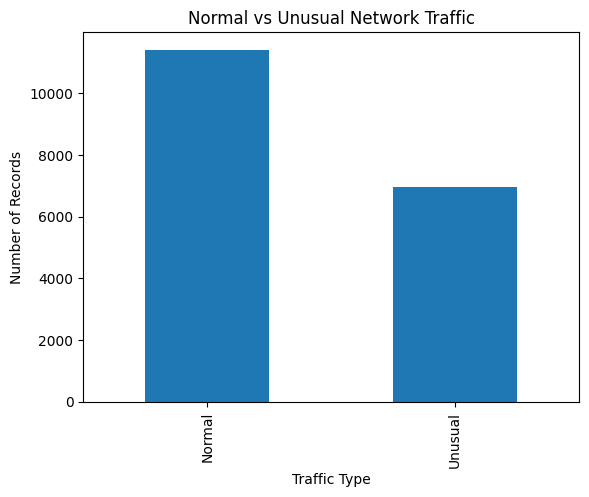

In [13]:
import matplotlib.pyplot as plt

df["Traffic"].value_counts().plot(kind="bar")
plt.title("Normal vs Unusual Network Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.show()